# TinyStories

In [1]:
from contextlib import nullcontext

import modal
import torch
from torch import nn

from artifacts.core.artifact import Resources
from artifacts.core.resolve import resolve
from artifacts.core.SGD.training import LoopConfig, LRSchedule, OptimizerParameters, TrainingParameters
from artifacts.mappeddataset import MappedDataSet
from artifacts.sources import SourceURL
from artifacts.stages.pretraining import Pretraining
from artifacts.tokenizers.bpe import Tokenizer as BPETokenizer
from models.transformer import Transformer
from profiling.profile_events import aggregate_kernels, display_steps, events_to_rows, launch_chain
from profiling.step_report import build_report
from profiling.util import phase, run_profile


In [2]:
HF = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main"
train = SourceURL(name="tinystories-train", url=f"{HF}/TinyStoriesV2-GPT4-train.txt")
valid = SourceURL(name="tinystories-valid", url=f"{HF}/TinyStoriesV2-GPT4-valid.txt")

tokenizer = BPETokenizer(
    vocab_size=10000,
    special_tokens=("<|endoftext|>",),
    sources=(valid,),
    allocated_resources=Resources(cpu=4),
)

dataset = MappedDataSet.from_sources(
    tokenizer=tokenizer,
    train_sources=(train,),
    valid_sources=(valid,),
)

pretraining = Pretraining(
    run_id="BMTHENRUN",
    dataset=dataset,
    model=Transformer(
        vocab_size=tokenizer.vocab_size,
        d_model=128,
        d_ff=256,
        sequence_length=32,
        num_layers=4,
        num_heads=16,
        rope_theta=10000,
        device="cuda",
        dtype="torch.float32",
    ),
    training_parameters=TrainingParameters(
        total_steps=20000,
        batch_size=64,
        max_norm=1.0,
        lr_schedule=LRSchedule(
            max_learning_rate=3e-4,
            min_learning_rate=3e-5,
            warmup_iters=200,
            cosine_cycle_iters=5000,
        ),
        optimizer="torch.optim.AdamW",
        optimizer_parameters=OptimizerParameters(
            lr=3e-4,
            betas=(0.9, 0.95),
            weight_decay=0.1,
            eps=1e-8,
        ),
        seed=0,
    ),
    loop_config=LoopConfig(
        checkpoint_every=5000,
        val_every=200,
        gpu_check_every=200,
    ),
    allocated_resources=Resources(gpu_type="T4", gpu_count=1),
)

## Declare

In [3]:
for artifact in resolve(pretraining):
    print(f"{type(artifact).__name__:16} {artifact.artifact_path}")

SourceURL        sources/tinystories-train
SourceURL        sources/tinystories-valid
Tokenizer        tokenizers/bpe-10000-b46983c6f3
TokenizedSource  tokenized/bpe-10000-b46983c6f3/tinystories-train
TokenizedSource  tokenized/bpe-10000-b46983c6f3/tinystories-valid
MappedDataSet    mappeddatasets/mapped-2be543ce28
Pretraining      runs/BMTHENRUN/pretraining/0-20000-9b83721f03


In [29]:
if modal.is_local():
    from local import declare_on_volume as declare
else:  # in the lab, on the volume itself
    from lab import declare

report = declare(pretraining, verbose=True, commit=True)  # commit=True publishes

sources/tinystories-train                         done  (drift: 73684a0 -> f3a22b3)
sources/tinystories-valid                         done  (drift: f9752b6 -> f3a22b3)
tokenizers/bpe-10000-b46983c6f3                   done  (drift: f9752b6 -> f3a22b3)
tokenized/bpe-10000-b46983c6f3/tinystories-train  done  (drift: f9752b6 -> f3a22b3)
tokenized/bpe-10000-b46983c6f3/tinystories-valid  done  (drift: f9752b6 -> f3a22b3)
mappeddatasets/mapped-2be543ce28                  done  (drift: f9752b6 -> f3a22b3)
runs/BMTHENRUN/pretraining/0-20000-9b83721f03     declared

1 declared, 6 done
ok -- 0 to declare


## Benchmark

In [3]:
def profiling_step_loop(model, optimizer, tokens, *, autocast, spans):
    """Runs one training step on tokens, each phase in phase(name, spans)."""
    with phase("zero_grad", spans):
        optimizer.zero_grad(set_to_none=True)
    with torch.autocast("cuda", dtype=autocast) if autocast else nullcontext():  # backward and the optimizer run outside autocast
        with phase("forward", spans):
            logits = model(tokens)
        with phase("loss", spans):
            # Next-token prediction: each position predicts the following input token.
            loss = nn.functional.cross_entropy(logits[:, :-1].reshape(-1, logits.shape[-1]), tokens[:, 1:].reshape(-1))
    with phase("backward", spans):
        loss.backward()
    with phase("optimizer_step", spans):
        optimizer.step()

In [9]:
captured = run_profile(
    pretraining.allocated_resources,
    model_declaration=pretraining.model,
    training_parameters=pretraining.training_parameters,
    profiling_step_loop=profiling_step_loop,
    batch_size=pretraining.training_parameters.batch_size,
    warmup_steps=5,
    profile_steps=2,
    autocast=None,  # PretrainJob trains without autocast
    kernel_events=True,
    module_scopes=True,
    peak_memory=True,
    trace_memory=True,
)

profile call fc-01M5NDDHV7G75T6G3QA53SHQ99
INFO profile: Transformer on Tesla T4, batch_size 64
INFO profile: warmup: 5 steps
INFO profile: step 0: 150.5 ms
INFO profile: step 1: 150.4 ms
INFO profile: done


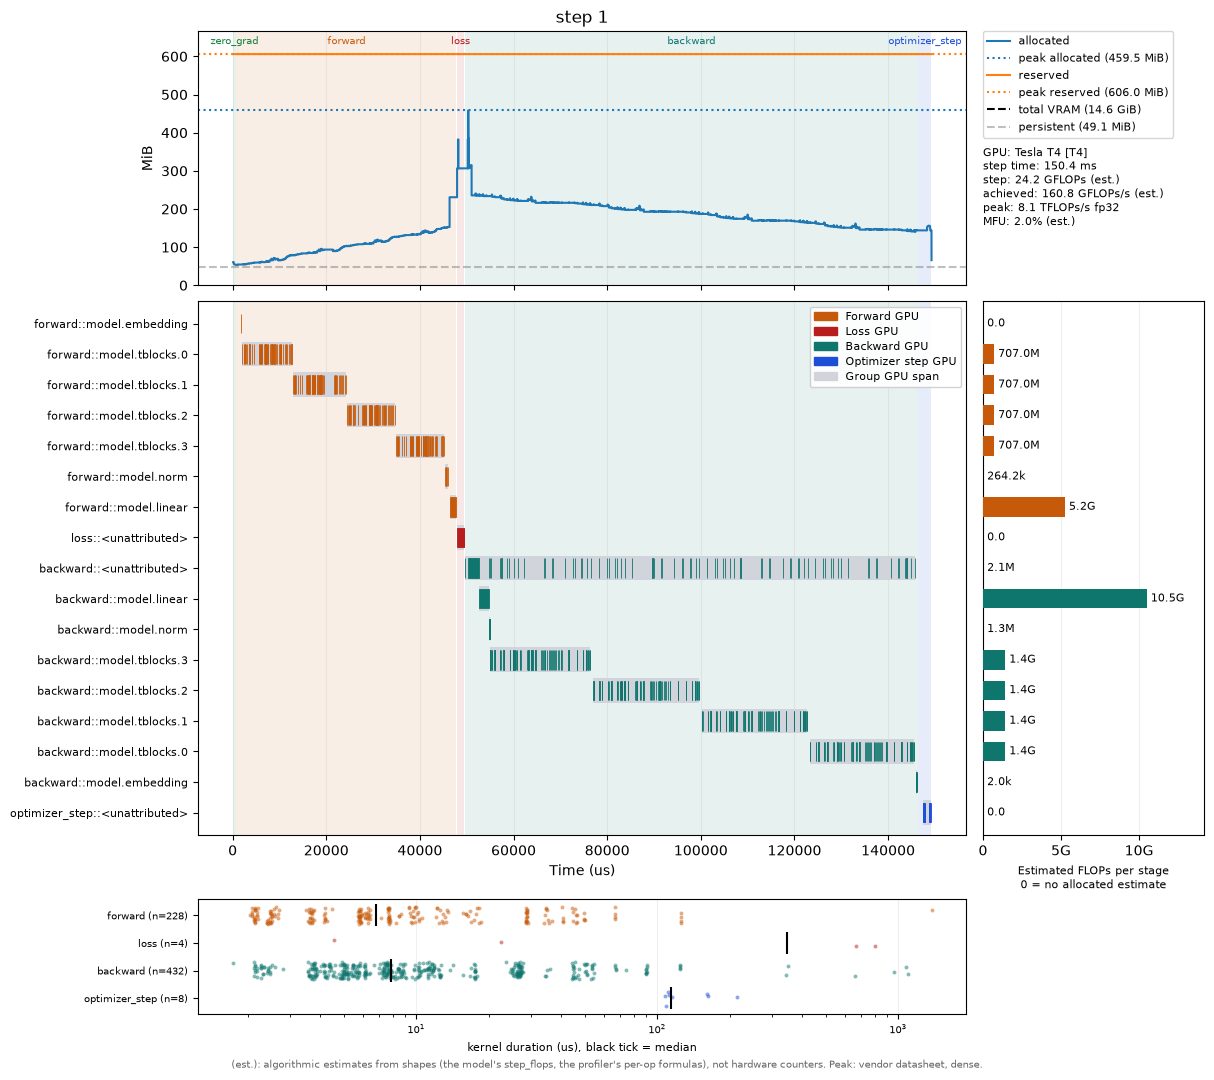

In [25]:
report = build_report(captured, depth=3)
display_steps(report, steps=[1])

In [26]:
step = max(captured["steps"])
rows = events_to_rows(captured["steps"][step]["events"])
groups, kernels, unattributed_kernels, flop_sources = aggregate_kernels(rows, depth=3)
display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", "estimated_flops"]])

kernel_count  gpu_time_us  gpu_span_us  \
phase          module_fqn                                                
forward        model.embedding             1       10.592       10.592   
               model.linear                1     1374.112     1374.112   
               model.norm                  6       34.400      541.503   
               model.tblocks.0            55      836.545    10506.557   
               model.tblocks.1            55      838.752    11455.805   
               model.tblocks.2            55      838.752    10096.829   
               model.tblocks.3            55      837.824    10274.462   
loss           <unattributed>              4     1494.975     1497.983   
backward       <unattributed>             84     2925.728    96092.739   
               model.embedding             7       65.600      258.816   
               model.linear                2     2177.376     2181.920   
               model.norm                 15      115.040      141.696   
               model.tblocks.0            81     1526.399    22339.641   
               model.tblocks.1            81     1531.579    22451.769   
               model.tblocks.2            81     1529.793    22595.641   
               model.tblocks.3            81     1528.513    21390.554   
optimizer_step <unattributed>              8     1091.264     1787.488   

                                estimated_flops  
phase          module_fqn                        
forward        model.embedding     0.000000e+00  
               model.linear        5.242880e+09  
               model.norm          2.641920e+05  
               model.tblocks.0     7.070075e+08  
               model.tblocks.1     7.070075e+08  
               model.tblocks.2     7.070075e+08  
               model.tblocks.3     7.070075e+08  
loss           <unattributed>      0.000000e+00  
backward       <unattributed>      2.097152e+06  
               model.embedding     2.048000e+03  
               model.linear        1.048576e+10  
               model.norm          1.314816e+06  
               model.tblocks.0     1.416110e+09  
               model.tblocks.1     1.416110e+09  
               model.tblocks.2     1.416110e+09  
               model.tblocks.3     1.416110e+09  
optimizer_step <unattributed>      0.000000e+00

In [27]:
display(kernels[["name", "phase", "module_fqn", "owner_fqn", "gpu_start_us", "duration_us"]])

,name,phase,module_fqn,owner_fqn,gpu_start_us,duration_us
index,,,,,,
14,"void at::native::vectorized_gather_kernel<16, ...",forward,model.embedding,model.embedding,3337.298,10.592
2039,volta_sgemm_128x128_tn,forward,model.linear,model.linear,48006.084,1374.112
1987,void at::native::vectorized_elementwise_kernel...,forward,model.norm,model.norm,47009.157,4.480
1990,"void at::native::reduce_kernel<512, 1, at::nat...",forward,model.norm,model.norm,47116.420,9.888
1993,void at::native::vectorized_elementwise_kernel...,forward,model.norm,model.norm,47205.508,2.208
...,...,...,...,...,...,...
8757,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,149446.629,160.480
8915,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,150296.069,112.320
8920,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,150409.637,114.560


In [13]:
kernel_id = report["steps"][str(step)]["kernels"]["id"][0]
display(launch_chain(rows, kernel_id, format=True))

,name,activity_type,device_type,start_us,end_us,launcher_id,correlation_id,linked_correlation_id,flops,input_shapes,input_dtypes
index,,,,,,,,,,,
5,train::forward,user_annotation,DeviceType.CPU,2403.285,49419.508,<NA>,18947,0,0,[],[]
7,forward::model,user_annotation,DeviceType.CPU,2476.661,48324.076,5,18948,0,0,[],[]
8,forward::model.embedding,user_annotation,DeviceType.CPU,2556.144,3484.993,7,18949,0,0,[],[]
9,aten::index,cpu_op,DeviceType.CPU,2613.241,3350.831,8,18950,0,0,"[[10000, 128], []]","[float, ]"
13,cudaLaunchKernel,cuda_runtime,DeviceType.CPU,2713.755,3341.272,9,87964,18950,0,[],[]
14,"void at::native::vectorized_gather_kernel<16, ...",kernel,DeviceType.CUDA,3337.298,3347.890,13,87964,18950,0,[],[]
